In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


In [3]:
img = cv2.imread('StainImages/Zoernikav folio212.jpg')

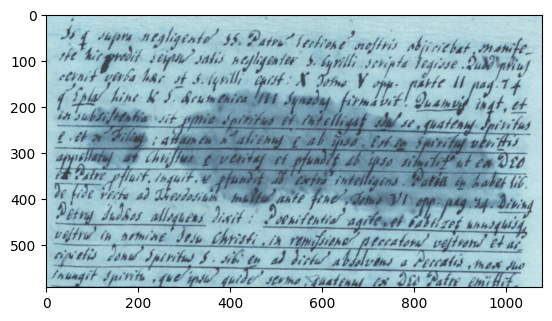

In [4]:
plt.imshow(img)


In [5]:
# do otsu based binarization
cv2.imshow('Original Image', img)
# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2.imshow('Grayscale Image', gray)
# Apply Otsu's thresholding
ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
cv2.imshow('Binarized Image', thresh)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [6]:
# Otsu's thresholding after Gaussian filtering
blur = cv2.GaussianBlur(gray, (5, 5), 0)
ret, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
cv2.imshow('Binarized Image', thresh)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [7]:
# optional: make black more intense
gray = cv2.convertScaleAbs(gray, alpha=1.5, beta=0)
cv2.imshow('Enhanced Grayscale Image', gray)
cv2.waitKey(0)
cv2.destroyAllWindows()

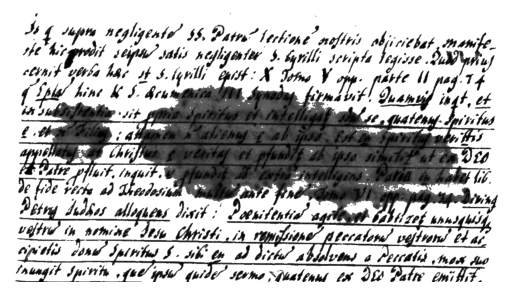

In [8]:
# now apply histogram equalization to enhance contrast
H = cv2.equalizeHist(gray)
plt.imshow(H, cmap='gray')
plt.axis('off')
plt.show()

In [9]:
import sys
!{sys.executable} -m pip install scikit-image

^C



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
# Illumination correction
bg = cv2.GaussianBlur(gray, (0, 0), sigmaX=25)
norm = cv2.divide(gray, bg, scale=255)

# Denoise
norm = cv2.bilateralFilter(norm, d=5, sigmaColor=30, sigmaSpace=30)

# --- Sauvola (middle ground) ---
window_size = 35     # between 25 (broken) and 51 (too connected)
k = 0.10             # between 0.2 (thin) and 0.05 (thick)
R = 128.0

norm_f = norm.astype(np.float32)

mean = cv2.boxFilter(norm_f, -1, (window_size, window_size), normalize=True)
mean_sq = cv2.boxFilter(norm_f * norm_f, -1, (window_size, window_size), normalize=True)
var = np.clip(mean_sq - mean * mean, 0, None)
std = np.sqrt(var)

threshold_surface = mean * (1 + k * ((std / R) - 1))
binary = np.where(norm_f > threshold_surface, 255, 0).astype(np.uint8)

cv2.imwrite('adaptive_better.png', binary)
cv2.imshow('Better Adaptive Thresholding', binary)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [12]:
def background_normalize(gray, sigma=25, method='divide'):
    """
    Flat-field / background normalization.
    Removes low-frequency illumination gradients.
    """
    # Estimate background with a large Gaussian
    bg = cv2.GaussianBlur(gray, (0, 0), sigmaX=sigma)

    if method == 'divide':
        # Division: most common for documents
        norm = cv2.divide(gray, bg, scale=255)
    elif method == 'subtract':
        # Subtraction: preserves additive noise model
        norm = cv2.subtract(gray, bg)
        norm = cv2.normalize(norm, None, 0, 255, cv2.NORM_MINMAX)
    return norm.astype(np.uint8)


def background_normalize_morph(gray, kernel_size=51):
    """
    Morphological background estimation (rolling-ball alternative).
    Better for text documents with large glyphs.
    """
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    bg = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, kernel)
    norm = cv2.divide(gray, bg, scale=255)
    return norm.astype(np.uint8)

In [13]:
def sauvola(gray, window=35, k=0.10, R=128.0):
    """
    Sauvola local adaptive thresholding using integral images.
    Fast: O(N) regardless of window size.
    """
    img = gray.astype(np.float32)

    # Local mean and mean of squares via box filters
    mean = cv2.boxFilter(img, -1, (window, window), normalize=True)
    mean_sq = cv2.boxFilter(img * img, -1, (window, window), normalize=True)

    var = np.clip(mean_sq - mean * mean, 0, None)
    std = np.sqrt(var)

    # Sauvola threshold surface
    T = mean * (1.0 + k * ((std / R) - 1.0))

    binary = np.where(img > T, 255, 0).astype(np.uint8)
    return binary

In [14]:
def tri_level_thresholding(gray, debug=False):
    """
    Tri-level semi-adaptive binarization from Shobha Rani et al. (2022).

    Level 1: mean-based threshold  -> removes uneven illumination / shadows
    Level 2: median-based threshold -> removes impulse & periodic noise
    Level 3: intensity-slicing threshold -> removes stain marks on text
    """
    # ---------- Pre-enhancement: contrast stretching ----------
    # Stretch grayscale to full [0, 255] dynamic range
    enhanced = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    # ---------- Gradient image (via RGB slicing) ----------
    # For a grayscale-only input, we approximate the "gradient image" by
    # edge-emphasising: the paper's RGB slice G - (R+B)/2 highlights text.
    # If you have a color image, use the real formula below.
    #   Id = IG - (IR + IB) / 2
    #   Iref = Otsu(Id)
    #   Gd = original image with Iref==1 pixels zeroed
    gd = enhanced.copy()  # fallback when only grayscale is available

    # ---------- Level 1: mean threshold ----------
    # Paper: T1 = (1/n) * sum(p(r_i) * r_i) over non-zero-probability grey levels
    # i.e. the mean of the non-empty histogram bins.
    hist = cv2.calcHist([gd], [0], None, [256], [0, 256]).flatten()
    nonzero_levels = np.nonzero(hist)[0]
    # Weighted mean over only present grey levels
    if nonzero_levels.size > 0:
        T1 = int(round(hist[nonzero_levels].dot(nonzero_levels) / hist[nonzero_levels].sum()))
    else:
        T1 = int(enhanced.mean())

    g1 = np.where(enhanced >= T1, 255, 0).astype(np.uint8)

    # ---------- Level 2: median threshold ----------
    # Paper: threshold = median of the distinct grey levels in g1
    g1_f = g1.astype(np.float32)
    unique_vals = np.unique(g1_f)
    T2 = float(np.median(unique_vals))

    g2 = np.where(g1_f >= T2, 255, 0).astype(np.uint8)

    # ---------- Level 3: intensity-slicing threshold ----------
    # Paper: split sorted distinct grey levels of g2 into 4 equal partitions,
    # and use the mean of partition 2 (p2) as the threshold.
    vals = np.unique(g2)
    if vals.size >= 4:
        partitions = np.array_split(vals, 4)
        T3 = float(np.mean(partitions[1]))  # mean of p2
    else:
        T3 = float(np.mean(vals))

    g3 = np.where(g2.astype(np.float32) >= T3, 255, 0).astype(np.uint8)

    if debug:
        print(f"T1 (mean)    = {T1}")
        print(f"T2 (median)  = {T2}")
        print(f"T3 (slice)   = {T3}")
        return g1, g2, g3, (T1, T2, T3)
    return g3

In [15]:
def gradient_image_from_rgb(bgr):
    """
    Compute the 'gradient image' Gd used by the paper:
        Id = IG - (IR + IB) / 2
        Iref = Otsu(Id)
        Gd = copy of original with Iref==1 pixels set to 0
    """
    b, g, r = cv2.split(bgr.astype(np.float32))
    id_img = g - (r + b) / 2.0
    id_u8 = cv2.normalize(id_img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    _, iref = cv2.threshold(id_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    gd = bgr.copy()
    mask = iref == 255
    gd[mask] = 0
    return gd, iref, id_u8

In [16]:
def pseudo_coloring(g3, gd, min_area=500):
    """
    Pseudo-colouring stage:
    - Otsu on gradient image -> temp mask
    - Keep only connected components larger than min_area -> Bd
    - Threshold Bd-region pixels of g3 at 0.5 * mean(g3)
    """
    # Binary mask from gradient image
    _, temp = cv2.threshold(gd, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Filter tiny components
    n, labels, stats, _ = cv2.connectedComponentsWithStats(temp, connectivity=8)
    bd = np.zeros_like(temp)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            bd[labels == i] = 255

    # Threshold = mean(g3) / 2
    thr = 0.5 * float(g3.mean())

    g4 = np.zeros_like(g3)
    g4[(bd == 255) & (g3 >= thr)] = 255
    # Pixels outside mask keep original g3 value
    g4[bd == 0] = g3[bd == 0]
    return g4, bd


def post_enhance(binary):
    """
    Morphological bridging + dilation (paper's final step).
    """
    # Bridging: close small gaps between strokes
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2))
    bridged = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    # Light dilation to thicken faint strokes
    dilated = cv2.dilate(bridged, kernel, iterations=1)
    return dilated

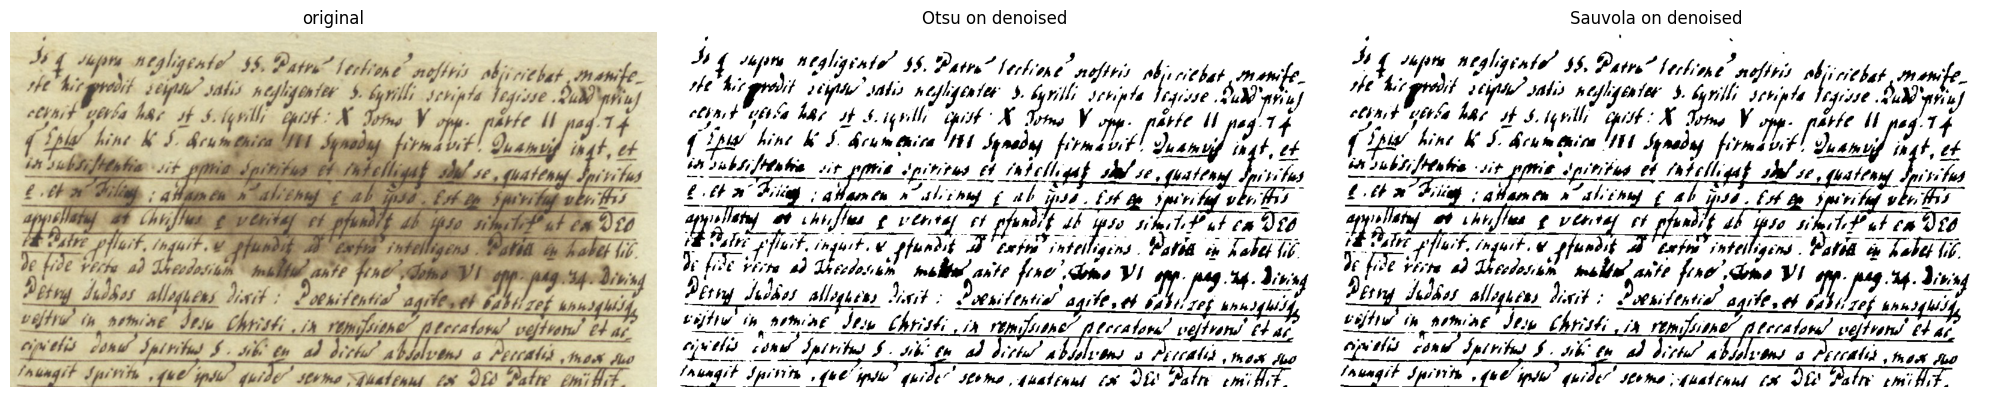

In [26]:
def restore_document(image_path,
                     bg_sigma=25,
                     sauvola_window=35,
                     sauvola_k=0.10,
                     use_tri_level=True):
    """
    Complete restoration pipeline:
      read -> background normalize -> denoise -> binarize -> post-enhance
    """
    bgr = cv2.imread(image_path)
    if bgr is None:
        raise FileNotFoundError(image_path)

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    # --- 1. Background normalization ---
    norm = background_normalize(gray, sigma=bg_sigma, method='divide')

    # --- 2. Edge-preserving denoise ---
    den = cv2.bilateralFilter(norm, d=5, sigmaColor=30, sigmaSpace=30)

    # --- 3. Binarization ---
    if use_tri_level:
        # Real paper pipeline: build gradient image from RGB first
        gd, iref, id_img = gradient_image_from_rgb(bgr)
        gd_gray = cv2.cvtColor(gd, cv2.COLOR_BGR2GRAY)

        g1, g2, g3, Ts = tri_level_thresholding(gd_gray, debug=True)

        g4, bd = pseudo_coloring(g3, gd_gray, min_area=500)
        binary = post_enhance(g4)
    else:
        binary = sauvola(den, window=sauvola_window, k=sauvola_k)

    return {
        'original': bgr,
        'gray': gray,
        'normalized': norm,
        'denoised': den,
        'binary': binary,
    }


if __name__ == "__main__":
    results = restore_document('StainImages/Zoernikav folio212.jpg', use_tri_level=False)
    den = results['denoised']

    _, otsu = cv2.threshold(den, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    sau = sauvola(den, window=35, k=0.10)

    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    for ax, img, title in zip(axes, [cv2.cvtColor(results['original'], cv2.COLOR_BGR2RGB), otsu, sau],
                            ['original', 'Otsu on denoised', 'Sauvola on denoised']):
        ax.imshow(img, cmap='gray'); ax.set_title(title); ax.axis('off')
    plt.tight_layout(); plt.show()

In [31]:
cv2.imshow('sauvola on denoised', results['binary'])
cv2.waitKey(0)
cv2.destroyAllWindows()

In [25]:
def clean_for_reading(gray, close_size=45, gamma=1.4):
    # estimate the paper + stain (closing removes the dark text, keeps the background)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_size, close_size))
    bg = cv2.medianBlur(cv2.morphologyEx(gray, cv2.MORPH_CLOSE, k), 31)
    flat = cv2.divide(gray, bg, scale=255).astype(np.float32) / 255

    # stretch contrast: darkest 1% -> black, paper -> white, keep the greys
    lo, hi = np.percentile(flat, 1), np.percentile(flat, 60)
    flat = np.clip((flat - lo) / (hi - lo), 0, 1) ** gamma
    return (flat * 255).astype(np.uint8)

gray = cv2.cvtColor(cv2.imread('StainImages/Zoernikav folio212.jpg'), cv2.COLOR_BGR2GRAY)
readable = clean_for_reading(gray)
cv2.imwrite('readable.png', readable)   # open this file at 100% zoom

True